<img src="https://raw.githubusercontent.com/carubbi/MQ/b58af070c45fb17b77640c06c0016859ad366b4d/notebooks/assets/imgs/UNIFOR_logo.png" width="400">
<br>
<b>
<font size="6" face="arial" color="blue">
    Graduação em Ciência da Computação
</font>
</b>
<br>
<b>
<font size="4" face="arial">
    Disciplina: Métodos Quantitativos em Computação
</font>
</b>

**Orientador: Prof. Me. Ricardo Carubbi** <br>
*Docente da Graduação e Pós-Graduação em Ciência de Dados e Inteligência Artificial*<br>
*Laboratório de Ciência de Dados e Inteligência Artificial*<br>
*Universidade de Fortaleza*<br>

# Unidade III: Estatística inferencial

Na **Unidade I**, usamos tabelas, gráficos e medidas como a média e a proporção para descrever os dados observados. Na **Unidade II**, estudamos como modelos de probabilidade, como a Binomial e a Normal, descrevem os resultados possíveis de um fenômeno aleatório.

A **estatística inferencial** reúne essas ideias para tirar conclusões sobre uma **população** a partir de uma **amostra**. Amostras obtidas pelo mesmo procedimento podem produzir médias e proporções diferentes. Usamos a probabilidade para estudar essa **variabilidade amostral** e quantificar a incerteza que ela traz às conclusões (Barbetta; Reis; Bornia, 2010, cap. 7 e 8).

Nesta parte da Unidade III, usamos a mesma população simulada de rendimentos em salários mínimos da [parte de amostragem e distribuições amostrais](u3_s01.ipynb). A partir dela, estimamos a renda média e a proporção de pessoas com rendimento domiciliar per capita abaixo de **cinco salários mínimos (5 SM)**. Os **intervalos de confiança** expressam a precisão das estimativas. Os **testes de hipóteses** avaliam afirmações sobre os parâmetros. As curvas de poder relacionam a diferença de interesse ao tamanho da amostra.

## 1. Objetivos de aprendizagem

Ao final desta parte, o aluno será capaz de:

- Estimar média e proporção populacionais, interpretando intervalos de confiança e sua precisão.
- Testar hipóteses sobre média e proporção, verificando condições e comunicando evidência, magnitude e limitações.
- Relacionar o poder do teste à diferença de interesse e ao tamanho da amostra.

## 2. Agenda

**Aula 2: Estimação e testes (100 min)**

1. Estimador, estimativa, viés e precisão (10 min)
2. Intervalo de confiança para proporção (15 min)
3. Intervalo de confiança para média (15 min)
4. Raciocínio dos testes: hipóteses, referência, valor-p e erros (20 min)
5. Teste para proporção populacional (20 min)
6. Teste para média populacional, poder do teste e planejamento do tamanho da amostra (20 min)

As rotinas de geração da população, seleção aleatória, simulação, gráficos e conferência por pacotes são fornecidas prontas. Em sala, desenvolveremos funções curtas e interpretações dos resultados. As leituras e os exercícios de estudo serão realizados fora desses tempos.

## 3. Importações e configurações

In [1]:
# Importa as bibliotecas utilizadas nas duas aulas.
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestPower
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from IPython.display import display

In [2]:
# Define a precisão de exibição das tabelas.
pd.options.display.float_format = '{:.6f}'.format

# Define o estilo dos gráficos do notebook.
plt.rcParams.update({
    'figure.figsize': (9, 3.8),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': False,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#888888',
    'font.size': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 10,
    'legend.title_fontsize': 10,
    'legend.frameon': False,
    'axes.prop_cycle': plt.cycler(
        color=['#222222', '#666666', '#999999', '#cccccc']
    ),
})

In [3]:
def criar_paineis(linhas, colunas, *, sharex=False, sharey=False):
    """Dimensiona a figura a partir do tamanho de um painel."""
    largura, altura = plt.rcParams['figure.figsize']
    return plt.subplots(
        linhas, colunas, figsize=(colunas * largura, linhas * altura),
        sharex=sharex, sharey=sharey,
    )


def ajustar_layout_paineis(fig):
    """Ajusta a fonte à largura da figura exibida no notebook."""
    largura_base = plt.rcParams['figure.figsize'][0]
    fator = fig.get_figwidth() / largura_base
    if fator != 1:
        fig.draw_without_rendering()
        for texto in fig.findobj(match=plt.Text):
            texto.set_fontsize(texto.get_fontsize() * fator)
    fig.tight_layout()

In [4]:
# Define a variância da média com ou sem reposição.
def var_med(var, n, N, rep):
    """Calcula a variância da média usando a variância populacional."""
    if var < 0 or n <= 0 or N <= 0:
        raise ValueError("var deve ser não negativa e N e n devem ser positivos.")
    if not rep and (N <= 1 or n > N):
        raise ValueError("Sem reposição, exigir N > 1 e n <= N.")

    # Aplica a correção para população finita na seleção sem reposição.
    fc = 1 if rep else (N - n) / (N - 1)
    return var / n * fc

# Define o erro-padrão da média com ou sem reposição.
def ep_med(dp, n, N, rep):
    """Calcula a raiz da variância da média."""
    if dp < 0:
        raise ValueError("dp deve ser não negativo.")
    return math.sqrt(var_med(dp ** 2, n, N, rep=rep))

# Define o erro-padrão da proporção com ou sem reposição.
def ep_prop(p, n, N, rep):
    """Usa a variância Bernoulli p(1-p) no cálculo do erro-padrão."""
    if not 0 <= p <= 1:
        raise ValueError("p deve estar entre 0 e 1.")
    return math.sqrt(var_med(p * (1 - p), n, N, rep=rep))

## 4. Geração da população simulada

### 4.1. Modelo e reprodutibilidade

Construiremos uma população hipotética de $N=10\,000$ pessoas. A variável simulada será o rendimento mensal domiciliar per capita, isto é, a **renda do domicílio por morador**. Esse rendimento será expresso em múltiplos de um salário mínimo de referência, indicado por SM, sem conversão para reais. Usaremos o modelo Exponencial com taxa $\lambda=1/3$, cuja média é 3 SM e cuja variância é 9 SM². Esse modelo produz muitas rendas baixas e poucas rendas elevadas. A escolha do modelo se apoia na simulação apresentada por Pinheiro et al. (2009). Sua interpretação como renda é uma adaptação didática.

A semente 43 fixa a população gerada. As seleções amostrais e as simulações terão geradores próprios, com sementes registradas nas respectivas células. Os dados serão gerados em memória, sem leitura ou gravação de CSV.

### 4.2. Classes de renda

Adotamos as seguintes classes didáticas de rendimento domiciliar per capita, em SM:

- **A:** mais de 20 SM.
- **B:** mais de 10 até 20 SM.
- **C:** mais de 4 até 10 SM.
- **D:** mais de 2 até 4 SM.
- **E:** até 2 SM.

In [5]:
# Gera as rendas da população com semente registrada.
N = 10_000
rng_pop = np.random.default_rng(43)
renda = rng_pop.exponential(scale=3, size=N)

# Classifica a renda em classes didáticas fixas.
classes = ['A', 'B', 'C', 'D', 'E']
pop = pd.DataFrame({'ID': np.arange(1, N + 1), 'Renda (SM)': renda})
pop['Classe'] = pd.cut(
    renda, bins=[0, 2, 4, 10, 20, np.inf],
    labels=classes[::-1], right=True, include_lowest=True,
)

# Exibe as primeiras linhas da população simulada.
display(pop.head(10).set_index('ID').rename(columns={'Renda (SM)': 'R (SM)'}))

,R (SM),Classe
ID,,
1,0.496383,E
2,0.257877,E
3,0.160291,E
4,3.573698,D
5,4.661569,C
6,1.212678,E
7,4.027507,C
8,0.361432,E
9,3.206388,D


**Tabela 1 - Primeiros dez registros da população simulada.** Cada pessoa possui identificador, rendimento domiciliar per capita e classe de renda de A a E. A população completa contém 10.000 pessoas. **Legenda.** ID = identificador da pessoa. R = rendimento domiciliar per capita. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

## 9. Estimador, estimativa, viés e precisão

### 9.1. Contexto

Na pesquisa sobre renda, a média de uma amostra é usada para estimar o rendimento domiciliar per capita médio da população. Outra amostra poderia fornecer uma estimativa diferente.

Em sucessivas repetições, essas estimativas se concentram em torno da média populacional? Quanto elas variam entre si?

Essa análise permite avaliar o **viés**, relacionado à tendência de superestimar ou subestimar a média populacional, e a **precisão**, maior quando as estimativas variam menos entre amostras.

### 9.2. Fundamentação teórica

Um **estimador** é uma **regra aplicada a uma amostra aleatória**. Sua **estimativa** é o **resultado observado depois da coleta**. Para um parâmetro genérico, o estimador e seu viés são representados por

$$
\widehat\theta=T(X_1,\ldots,X_n),\qquad
\operatorname{Viés}(\widehat\theta)=\mathbb E[\widehat\theta]-\theta.
\tag{2.1}
$$

$\theta$ é o parâmetro populacional, $\widehat\theta$ é o estimador aleatório e $T$ é a regra de cálculo. A estimativa observada é $\hat\theta=T(x_1,\ldots,x_n)$. O viés tem a unidade do parâmetro.

Por exemplo, para estimar a renda média de uma população, podemos usar a regra de somar as rendas de uma amostra e dividir pelo número de pessoas observadas. Essa regra define a média amostral como **estimador** da média populacional. O valor obtido em uma amostra específica é uma **estimativa**. Outra amostra pode produzir uma estimativa diferente, mesmo usando o mesmo estimador.

Um estimador **não viesado** tem **esperança igual ao parâmetro**. A **precisão** depende de sua **dispersão em repetições**. Uma regra pode ter centro correto e dispersão elevada. A qualidade da seleção amostral também afeta o alcance das conclusões, conforme Barbetta, Reis e Bornia (2010).

<div style="max-width: 760px; margin: 0 auto; text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_figura_7_7.png" alt="Figura 10 - Viés e precisão na analogia dos tiros ao alvo. Da esquerda para a direita, T1 é não viesado e mais preciso, T2 é não viesado e menos preciso, e T3 é viesado apesar da concentração de suas estimativas. Fonte: BARBETTA; REIS; BORNIA, 2010." style="display: block; width: 100%; height: auto">
<div style="display: flex"><span style="width: 33.33%">(a)</span><span style="width: 33.33%">(b)</span><span style="width: 33.33%">(c)</span></div>
</div>

**Figura 10 - Viés e precisão na analogia dos tiros ao alvo.** O centro do alvo representa o parâmetro populacional, e cada ponto representa uma estimativa obtida em uma amostra. Em (a), $T_1$ produz estimativas pouco dispersas em torno do parâmetro, ilustrando ausência de viés e maior precisão. Em (b), $T_2$ também é não viesado, mas apresenta maior dispersão e menor precisão que $T_1$. Em (c), $T_3$ produz estimativas concentradas, porém deslocadas do parâmetro, ilustrando que maior precisão não elimina o viés. Fonte: BARBETTA; REIS; BORNIA, 2010.


### 9.3. Aplicação

Retome as 10.000 estimativas da média populacional obtidas para cada tamanho amostral, $n\in\{1,2,5,10,30,100\}$, com reposição. O gráfico a seguir permite comparar o centro e a dispersão dessas estimativas.

Compare a média das estimativas de cada grupo com a média populacional, indicada pela linha tracejada. Em seguida, observe quanto as estimativas variam entre amostras. O aumento de $n$ altera principalmente o centro ou a dispersão? Qual grupo apresenta maior precisão?

In [6]:
# Calcula a média da população e define o número de simulações.
mu = renda.mean()
n_sim = 10_000
seed = 47

# Simula médias amostrais para os seis tamanhos do painel, com semente registrada.
tam_fig = [1, 2, 5, 10, 30, 100]
rng_fig = np.random.default_rng(seed)
med_fig = {}
for n in tam_fig:
    med_fig[n] = rng_fig.choice(renda, size=(n_sim, n), replace=True).mean(axis=1)

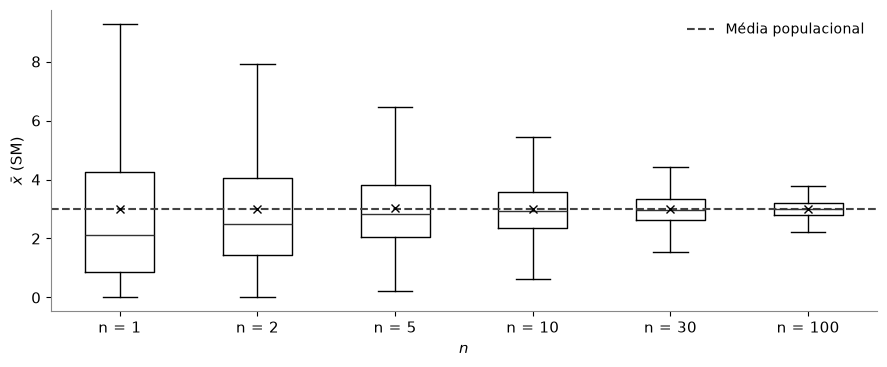

In [7]:
# Compara as estimativas dos seis tamanhos amostrais usados na Figura 8.
fig, ax = plt.subplots()
ax.boxplot([med_fig[n] for n in tam_fig], tick_labels=[f'n = {n}' for n in tam_fig], showmeans=True, showfliers=False,
           meanprops={'marker': 'x', 'markeredgecolor': 'black'},
           medianprops={'color': '#333333'})
ax.axhline(mu, color='#444444', linestyle='--', label='Média populacional')
ax.set(xlabel='$n$', ylabel=r'$\bar{x}$ (SM)')
ax.legend()
fig.tight_layout()
plt.show()

**Figura 11 - Dispersão das estimativas da média em amostras repetidas.** Os marcadores “x” pretos indicam as médias das 10.000 estimativas de cada grupo. As médias das estimativas permanecem próximas de 3,000 SM nos seis tamanhos amostrais. A dispersão diminui conforme $n$ aumenta, indicando maior precisão. Valores além dos limites dos boxplots não são exibidos como pontos. Fonte: CARUBBI, 2026.

#### 9.3.1. Interpretação

Nas condições do experimento, $\bar X$ é um estimador não viesado de $\mu$ para todos os tamanhos amostrais. A média das estimativas permanece próxima de 3,000 SM. A precisão aumenta com o tamanho amostral, pois a dispersão das médias amostrais diminui.

Uma estimativa particular pode ficar acima ou abaixo do parâmetro. Informar o erro-padrão ou um intervalo de confiança ajuda a comunicar a incerteza associada ao processo de estimação. Maior precisão, por si só, também não corrige uma seleção enviesada.

## 10. Intervalo de confiança para proporção

### 10.1. Contexto

Queremos estimar a proporção de pessoas da população simulada cujo rendimento domiciliar per capita é inferior a 5 salários mínimos (SM).

Em uma amostra aleatória simples com reposição, 315 das 400 observações apresentaram rendimento abaixo de 5 SM. A proporção amostral de 78,75% é a estimativa pontual da proporção populacional.

Outra amostra de mesmo tamanho, obtida pelo mesmo procedimento, poderia apresentar uma proporção diferente. Como usar o resultado observado para construir um intervalo de 95% de confiança para a proporção populacional?

### 10.2. Fundamentação teórica

**Da estimativa pontual ao intervalo de confiança**

Na amostra, 315 das 400 observações apresentaram rendimento domiciliar per capita abaixo de 5 SM. A proporção observada, **78,75%**, é a **estimativa pontual** da proporção populacional $p$. Como a proporção amostral varia de uma amostra para outra, podemos comunicar essa incerteza por meio de uma **estimativa intervalar**.

Um **intervalo de confiança ($IC$)** é uma faixa calculada com os dados da amostra para estimar um parâmetro populacional. O nível de confiança indica com que frequência esperamos que os intervalos obtidos pelo mesmo procedimento contenham o parâmetro em amostragens repetidas (Montgomery; Runger, 2018, p. 171–174).

Calculamos o intervalo de confiança para a proporção populacional pelo **método de Wald**. A **margem de erro** $ME$ é a distância entre a estimativa pontual e cada limite do intervalo. Os limites são calculados subtraindo a margem da estimativa e somando a margem à estimativa. O intervalo de confiança é, portanto, **simétrico em torno da estimativa pontual** (Brown; Cai; DasGupta, 2001, p. 103).

> **Abraham Wald (1902–1950)** foi matemático e professor de estatística na Universidade Columbia. Contribuiu para a teoria da decisão estatística e para o estudo de testes de hipóteses em grandes amostras (Wald, 1943; Zheng; Ying, 2012).

Nesta amostra, a margem de erro para 95% de confiança é de **4,01 pontos percentuais**. O **intervalo de confiança (IC) de 95%** vai de **74,74% a 82,76%** para a proporção de pessoas da população simulada com rendimento abaixo de 5 SM. A largura, dada pela diferença entre o limite superior e o inferior, é de **8,02 pontos percentuais**. A **Figura 12** mostra a estimativa pontual e a margem de erro de cada lado.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/ic_proporcao_95.png" alt="Intervalo de 95% de 74,74% a 82,76%, com centro em 78,75% e margem de erro de 4,01 pontos percentuais de cada lado." style="width: 760px; max-width: 100%; height: auto">
</div>

**Figura 12 - Intervalo de confiança de 95% para a proporção com rendimento abaixo de 5 SM.** O ponto indica a estimativa amostral de 78,75%. Cada seta representa a margem de erro de 4,01 pontos percentuais.

**O que significa 95% de confiança?**

Imagine repetir muitas vezes a amostragem de 400 observações e calcular um intervalo de confiança para cada amostra. Os limites variam de uma amostra para outra, e a proporção populacional $p$ é a mesma em todas as repetições. Quando a aproximação é adequada, cerca de 95% dos intervalos assim construídos contêm $p$. A **cobertura** é a probabilidade de o procedimento produzir um intervalo que contenha $p$ em uma repetição da amostragem. A **Figura 13** ilustra a cobertura em uma simulação com 50 amostras.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/ic_proporcao_cobertura.png" alt="Cinquenta intervalos de confiança de 95%. A linha tracejada marca 81,29%. Quarenta e oito intervalos contêm esse valor e dois ficam fora." style="width: 760px; max-width: 100%; height: auto">
</div>

**Figura 13 - Cobertura dos intervalos de confiança de 95% em amostras repetidas.** Cada segmento representa o intervalo de uma amostra de 400 observações, e cada ponto indica a proporção amostral. A linha tracejada marca a proporção populacional de 81,29%. Nesta simulação, 48 dos 50 intervalos contêm esse valor. A fração de intervalos que contêm a proporção populacional varia de uma simulação para outra.

> **“Há 95% de probabilidade de a proporção populacional $p$ estar entre 74,74% e 82,76%.” Essa afirmação é correta?**
>
> **Errada.** Depois que o intervalo é calculado, seus limites são fixos. A proporção populacional $p$ também é fixa e está dentro ou fora desses limites. Os **95% de confiança** indicam que, ao repetir a amostragem e aplicar o mesmo procedimento muitas vezes, esperamos que cerca de 95 em cada 100 intervalos contenham $p$, quando a aproximação é adequada.

**De onde vem a margem de erro?**

Na amostragem aleatória simples com reposição, denotamos por $\widehat P$ a proporção amostral antes de observar os dados e por $\hat p$ o valor obtido na amostra. Para uma amostra de tamanho $n$ e uma proporção populacional $0<p<1$, temos

$$
\mathbb E[\widehat P]=p,\qquad
\operatorname{Var}(\widehat P)=\frac{p(1-p)}{n},\qquad
\operatorname{EP}(\widehat P)=\sqrt{\frac{p(1-p)}{n}}.
\tag{2.5}
$$

O **erro-padrão** é o desvio-padrão da distribuição amostral de $\widehat P$. Ele mede quanto a proporção amostral varia entre amostras de mesmo tamanho.

O erro-padrão da equação (2.5) foi obtido da distribuição binomial da contagem $X$. Para estimá-lo com os dados da amostra, substituímos $p$ pela proporção amostral $\hat p$ (Montgomery; Runger, 2018, p. 185–186). Denotamos por $x$ o número de observações com o atributo de interesse.

$$
\hat p=\frac{x}{n},\qquad
\widehat{\operatorname{EP}}(\widehat P)
=\sqrt{\frac{\hat p(1-\hat p)}{n}}.
\tag{2.6}
$$

Denotamos o nível de confiança por $\gamma=1-\alpha$, com $0<\alpha<1$ (Barbetta; Reis; Bornia, 2010, p. 185). O valor $\alpha$ é a probabilidade nominal de não cobertura. Para 95% de confiança, temos $\alpha=0{,}05$. Como queremos um limite inferior e um superior para a proporção populacional, construímos um **intervalo bilateral**. Para escolher o valor crítico, usamos a Normal padrão como referência para o afastamento da proporção amostral em relação à proporção populacional, medido em erros-padrão. Usamos a região central da Normal padrão, com área $1-\alpha$. A área restante, $\alpha$, é dividida igualmente entre as duas caudas, com $\alpha/2$ em cada uma.

O **valor crítico** $z_{1-\alpha/2}$ é o ponto positivo no eixo $z$ da Normal padrão que deixa uma área acumulada de $1-\alpha/2$ à sua esquerda. Pela simetria da Normal padrão $Z\sim\mathcal N(0,1)$, a área entre os dois valores críticos é

$$
\mathbb P\left(-z_{1-\alpha/2}\leq Z\leq z_{1-\alpha/2}\right)=1-\alpha.
\tag{2.7}
$$

Para 95% de confiança, cada cauda tem área $0{,}025$. O limite positivo tem área acumulada de $0{,}975$, e o valor crítico correspondente é **$z_{0{,}975}\approx1{,}96$**. O **painel (a) da Figura 14** mostra a área central de 95% entre $-1{,}96$ e $1{,}96$ na escala padronizada. Nesse caso, a aproximação Normal indica que, em cerca de 95% das amostras, a proporção amostral fica a até 1,96 erros-padrão da proporção populacional.

No método de Wald, para um nível de confiança $1-\alpha$, a **margem de erro** é dada por

$$
\mathrm{ME}=z_{1-\alpha/2}\,\widehat{\operatorname{EP}}(\widehat P).
$$

O intervalo de confiança aproximado é

$$
IC=
\left[
\hat p-\mathrm{ME},\quad
\hat p+\mathrm{ME}
\right].
\tag{2.8}
$$

O **painel (b) da Figura 14** mostra o intervalo de 95% calculado com a amostra de renda.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/ic_proporcao_valor_critico.png" alt="Dois painéis. Em (a), a Normal padrão tem área central de 95% entre −1,96 e 1,96. Em (b), o intervalo da proporção vai de 74,74% a 82,76%, com centro em 78,75% e margem de erro de 4,01 pontos percentuais de cada lado." style="width: 760px; max-width: 100%; height: auto">
</div>

**Figura 14 - Valor crítico e intervalo de confiança de 95% para a proporção.** Em (a), os valores −1,96 e 1,96 delimitam a área central de 95% da Normal padrão. Em (b), multiplicar 1,96 pelo erro-padrão estimado produz a margem de erro de 4,01 pontos percentuais. Essa margem determina os limites de 74,74% e 82,76% em torno da proporção amostral de 78,75%.

**Como o nível de confiança afeta a largura?**

O nível de confiança é definido antes de examinar os resultados, de acordo com os objetivos do estudo. Para aumentar a confiança, precisamos de uma área central maior na Normal padrão e, portanto, de um valor crítico maior. A **Figura 15** relaciona diferentes níveis de confiança aos valores críticos da Normal padrão.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_figura_7_8.png" alt="Figura 15 - Área central da Normal padrão e valores críticos. A área central corresponde ao nível de confiança, e cada cauda contém metade da probabilidade restante. A tabela relaciona níveis de confiança aos valores críticos. Fonte: BARBETTA; REIS; BORNIA, 2010." style="width: 720px; max-width: 100%; height: auto">
</div>

**Figura 15 - Área central da Normal padrão e valores críticos.** A área sombreada representa o nível de confiança, denotado por $\gamma=1-\alpha$. Para 95%, ficam 2,5% em cada cauda e o valor crítico é aproximadamente 1,96. Para 99%, ficam 0,5% em cada cauda e o valor crítico sobe para aproximadamente 2,576. Na figura, $z_\gamma$ corresponde a $z_{1-\alpha/2}$ na notação do notebook. Barbetta, Reis e Bornia (2010).

No planejamento do estudo, definimos o **nível de confiança** e a **margem de erro aceitável** para responder à pergunta de pesquisa. Com a mesma amostra, um nível de confiança maior aumenta a margem de erro e produz um intervalo mais largo. Se o estudo exige maior confiança e a mesma margem de erro, é preciso planejar uma amostra maior (Barbetta; Reis; Bornia, 2010, p. 185–186; Montgomery; Runger, 2018, p. 186–187). Na seção 10.3, veremos esse efeito ao comparar os intervalos de 95% e 99% com os mesmos dados.

### 10.3. Aplicação

Use as 315 observações com rendimento abaixo de 5 SM, entre as 400 da amostra, para calcular o **IC de 95%** pelo método de Wald. Mostre a proporção amostral, o erro-padrão estimado, a margem de erro e os limites. Explique o que significam os 95% em amostragens repetidas.

Compare com o **IC de 99%**, obtido com a mesma amostra e o mesmo método, e explique a diferença de largura.

#### 10.3.1. Implementação sem pacotes

A função abaixo aplica a estrutura estimativa mais ou menos margem. O quantil será obtido pelo pacote.

In [8]:
# Mostra os cinco primeiros rendimentos domiciliares per capita em SM.
print(f"População simulada com {renda.size} observações.")
print("Primeiros dez valores (SM):", renda[:10].round(3))

População simulada com 10000 observações.
Primeiros dez valores (SM): [0.496 0.258 0.16  3.574 4.662 1.213 4.028 0.361 3.206 1.619]


In [9]:
# Define os limites de um intervalo simétrico em torno da estimativa.
def lim_ic(est, q, ep):
    """Calcula os limites do intervalo de confiança."""
    margem = q * ep
    return est - margem, est + margem

In [10]:
# Seleciona com reposição uma amostra de 400 observações.
n_inf = 400
rng_inf = np.random.default_rng(47)
am_inf = rng_inf.choice(renda, size=n_inf, replace=True)
x_inf = int((am_inf < 5).sum())
phat = x_inf / n_inf

# Calcula o IC de 95% pela expressão direta.
alfa_ic = 0.05
ep_phat = ep_prop(phat, n_inf, N, rep=True)
z_95 = stats.norm.ppf(1 - alfa_ic / 2)
ic_p95 = lim_ic(phat, z_95, ep_phat)

print(f'Pessoas com renda < 5 SM: {x_inf} em {n_inf}')
print(f'Proporção amostral = {phat:.4f}')
print(f'Erro-padrão estimado = {ep_phat:.6f}')
print(f'Margem de erro = {z_95 * ep_phat:.6f}')
print(f'IC de 95% = [{ic_p95[0]:.6f}, {ic_p95[1]:.6f}]')

Pessoas com renda < 5 SM: 315 em 400
Proporção amostral = 0.7875
Erro-padrão estimado = 0.020454
Margem de erro = 0.040089
IC de 95% = [0.747411, 0.827589]


#### 10.3.2. Implementação com pacotes

O argumento <code>method='normal'</code> seleciona o método de Wald. Usamos essa opção para conferir o intervalo de confiança de 95% calculado pela fórmula. O intervalo de 99% será apresentado pronto para interpretação. [Documentação de proportion_confint](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportion_confint.html) (STATSMODELS DEVELOPERS, 2025).

In [11]:
# Confere o IC de 95% e fornece o de 99% pelo mesmo método.
ic_p95_pac = proportion_confint(x_inf, n_inf, alpha=0.05, method='normal')
ic_p99 = proportion_confint(x_inf, n_inf, alpha=0.01, method='normal')
display(pd.DataFrame({
    'Proc.': ['Expr. 95%', 'Pac. 95%', 'Pac. 99%'],
    'LI': [ic_p95[0], ic_p95_pac[0], ic_p99[0]],
    'LS': [ic_p95[1], ic_p95_pac[1], ic_p99[1]],
}))

,Proc.,LI,LS
0,Expr. 95%,0.747411,0.827589
1,Pac. 95%,0.747411,0.827589
2,Pac. 99%,0.734814,0.840186


**Tabela 11 - Intervalos de confiança para a proporção com renda abaixo de 5 SM.** O IC de 95% vai de 74,74% a 82,76%. O IC de 99% vai de 73,48% a 84,02% e é mais largo para a mesma amostra. **Legenda.** Proc. = procedimento. Expr. = cálculo pela expressão. Pac. = cálculo pelo pacote statsmodels. LI e LS = limites inferior e superior da proporção. IC = intervalo de confiança. Os percentuais em Proc. indicam o nível de confiança. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

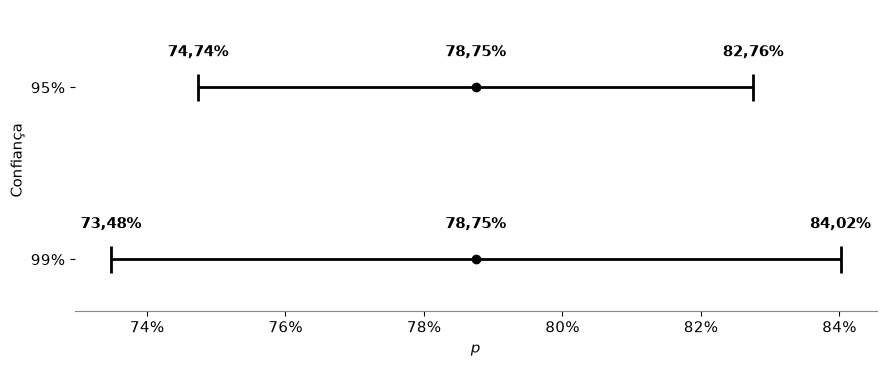

In [12]:
# Compara os intervalos de 95% e 99% na mesma escala.
fig, ax = plt.subplots()
intervalos = [ic_p99, ic_p95]

for y, (li, ls) in enumerate(intervalos):
    ax.hlines(y, li, ls, color='black', linewidth=2)
    ax.vlines([li, ls], y - 0.08, y + 0.08, color='black', linewidth=2)
    ax.plot(phat, y, 'o', color='black')

    for valor in (li, phat, ls):
        ax.text(
            valor, y + 0.16, f'{valor:.2%}'.replace('.', ','),
            ha='center', va='bottom', fontweight='bold',
        )

ax.set(
    xlabel='$p$',
    ylabel='Confiança',
    yticks=[0, 1], yticklabels=['99%', '95%'],
    ylim=(-0.3, 1.45),
)
ax.xaxis.set_major_formatter('{x:.0%}')
ax.spines['left'].set_visible(False)
fig.tight_layout()
plt.show()

**Figura 16 - Intervalos de confiança de 95% e 99% para a proporção.** Os pontos indicam a mesma proporção amostral de 78,75%. O intervalo de 99% é mais largo para a mesma amostra. Fonte: CARUBBI, 2026.

#### 10.3.3. Interpretação

A amostra contém 315 pessoas com renda abaixo de 5 SM, correspondendo a 78,75%. As contagens de pessoas com e sem o atributo são suficientemente grandes para esta aplicação aproximada de Wald. O IC de 95% vai de **74,74% a 82,76%**.

O IC de 99% tem maior largura. A confiança descreve a cobertura do procedimento em amostras repetidas, sob suas condições. Ela não é a probabilidade de o parâmetro fixo pertencer a este intervalo já calculado.

Como conferência didática, a proporção da população completa é 81,29% e pertence aos dois intervalos observados. Essa ocorrência isolada não estima a cobertura do método.

## 11. Intervalo de confiança para média

### 11.1. Contexto

Queremos estimar o rendimento domiciliar per capita médio da população simulada. Na amostra de 400 observações da seção 10, a média foi de **3,135 SM** e o desvio-padrão amostral foi de **2,971 SM** (Tabela 12).

A média amostral varia entre amostras. Como construir um **intervalo de 95% de confiança** para a média populacional quando o desvio-padrão populacional é desconhecido?

In [13]:
# Resume a amostra comum às aplicações inferenciais.
display(pd.DataFrame({
    'n': [n_inf],
    'Mín (SM)': [am_inf.min()],
    'Máx (SM)': [am_inf.max()],
    'M (SM)': [am_inf.mean()],
    'DP (SM)': [am_inf.std(ddof=1)],
}))

,n,Mín (SM),Máx (SM),M (SM),DP (SM)
0,400,0.004660,18.894488,3.134665,2.970826


**Tabela 12 - Resumo das rendas na amostra de 400 pessoas.** Os valores mínimo e máximo descrevem a amplitude das rendas individuais. O intervalo a ser calculado estima a média populacional, sem pretender conter uma proporção especificada de rendas individuais. **Legenda.** n = número de pessoas na amostra. Mín e Máx = rendas mínima e máxima. M = renda média. DP = desvio-padrão amostral das rendas. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

### 11.2. Fundamentação teórica

Para a média, retomamos a estrutura **estimativa pontual ± margem de erro** apresentada na seção 10.2.

**Desvio-padrão populacional conhecido**

Para estimar a média populacional $\mu$, usamos a média amostral observada $\bar x$. Quando o desvio-padrão populacional $\sigma$ é conhecido, o erro-padrão da média é $\sigma/\sqrt n$. Para observações independentes de uma população Normal, a média amostral padronizada segue a Normal padrão (Montgomery; Runger, 2018, p. 173–174).

Para um nível de confiança $1-\alpha$, usamos o valor crítico $z_{1-\alpha/2}$. A margem de erro e o intervalo são dados por

$$
\mathrm{ME}=z_{1-\alpha/2}\frac{\sigma}{\sqrt n},
\qquad
IC=[\bar x-\mathrm{ME},\ \bar x+\mathrm{ME}].
\tag{2.9}
$$

Para 95% de confiança, o valor crítico é aproximadamente 1,96. A **Figura 17** mostra o valor crítico na escala da Normal padrão e a margem de erro na escala da média amostral.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/ic_media_dp_conhecido.png" alt="Dois painéis. Em (a), a Normal padrão tem área central de 95% entre −1,96 e 1,96. Em (b), o intervalo fica centrado na média amostral observada, com uma margem de erro de cada lado." style="width: 760px; max-width: 100%; height: auto">
</div>

**Figura 17 - Intervalo de confiança para a média com desvio-padrão populacional conhecido.** Em (a), os valores críticos −1,96 e 1,96 delimitam 95% da área da Normal padrão. Em (b), cada seta mostra a margem de erro entre a média amostral observada e um dos limites.

**Desvio-padrão populacional desconhecido**

Quando $\sigma$ é desconhecido, situação comum na prática, usamos o desvio-padrão amostral $s$ para estimar o erro-padrão da média por $s/\sqrt n$ (Barbetta; Reis; Bornia, 2010, p. 188). Para observações independentes de uma população Normal, o valor crítico vem da distribuição $t$ de Student, com $n-1$ graus de liberdade. A estatística padronizada e o intervalo são dados por

$$
T=\frac{\bar X-\mu}{S/\sqrt n}\sim t_{n-1},\qquad
IC_{1-\alpha}=\left[\bar x-t_{1-\alpha/2,n-1}\frac{s}{\sqrt n},\ \bar x+t_{1-\alpha/2,n-1}\frac{s}{\sqrt n}\right].
\tag{2.10}
$$

$\bar X$ é a média amostral aleatória e $\bar x$ é a média amostral observada. Na equação (2.10), $S$ representa o desvio-padrão amostral aleatório, e $s$ é seu valor calculado na amostra. $\mu$ é a média populacional e $t_{1-\alpha/2,n-1}$ é o valor crítico da distribuição $t$ com $n-1$ graus de liberdade. O **erro-padrão estimado** é $s/\sqrt n$, com a unidade da variável. Ao calcular os desvios em torno da média amostral, a soma dos desvios é zero, restando $n-1$ desvios livres.

Conhecer $s$ após observar a amostra continua sendo diferente de conhecer $\sigma$ populacional. A **distribuição $t$**  de Student considera a incerteza de estimar $\sigma$. A **distribuição Normal** é a referência para a média amostral padronizada com $\sigma$ conhecido sob as condições apropriadas. A **cobertura** do intervalo de confiança baseado na distribuição $t$ de Student coincide com o **nível de confiança nominal** quando as observações são **independentes e identicamente distribuídas segundo uma Normal**. Essa condição merece atenção especial em amostras pequenas (Barbetta; Reis; Bornia, 2010).

A **Figura 18** compara a distribuição $t$ de Student, para diferentes graus de liberdade, com a Normal padrão.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_figura_7_9.png" alt="Figura 18 - Distribuição t de Student e Normal padrão. As caudas da t são mais largas, com maior diferença para poucos graus de liberdade. O aumento dos graus de liberdade aproxima a t da Normal padrão. Fonte: Barbetta, Reis e Bornia (2010)." style="width: 720px; max-width: 100%; height: auto">
</div>

**Figura 18 - Distribuição t de Student e Normal padrão.** As caudas da $t$ são mais largas, com maior diferença para poucos graus de liberdade. O aumento dos graus de liberdade aproxima a $t$ da Normal padrão. Neste cálculo, os **graus de liberdade** indicam quanta informação fica disponível para estimar a variabilidade depois de calcular a média amostral. Como os $n$ desvios em relação à média somam zero, apenas $n-1$ podem variar livremente. Fonte da figura: Barbetta, Reis e Bornia (2010).

[Vídeo complementar sobre graus de liberdade](https://youtube.com/shorts/IeuEiUQ_yNQ?si=4jMkFOVMc3qn4OVr)

Para observações independentes de uma população não Normal com variância finita, o **Teorema Central do Limite** justifica aproximar a distribuição amostral da média por uma Normal à medida que $n$ aumenta. Em amostras grandes, o intervalo de confiança baseado na distribuição $t$ de Student pode ser usado com **cobertura aproximada**. A qualidade dessa aproximação depende do tamanho da amostra e da forma da distribuição populacional (Montgomery; Runger, 2018, p. 177–181).

### 11.3. Aplicação

Use a mesma amostra de 400 observações para calcular o **IC de 95%** para o rendimento domiciliar per capita médio da população simulada, com desvio-padrão populacional desconhecido. Calcule a média amostral, o desvio-padrão amostral e o erro-padrão estimado. Use o valor crítico da distribuição $t$ de Student para obter os limites.

A média amostral, o erro-padrão estimado e os graus de liberdade serão retomados no teste da seção 14.

#### 11.3.1. Implementação sem pacotes

As medidas descritivas são obtidas por NumPy, como nas aulas anteriores. A construção dos limites reutiliza a função desenvolvida na seção 10.

In [14]:
# Calcula a média, o desvio-padrão amostral e o erro-padrão estimado.
n_inf = len(am_inf)
media_t = am_inf.mean()
s_t = am_inf.std(ddof=1)
ep_t = ep_med(s_t, n_inf, N, rep=True)

# Calcula os limites do intervalo bilateral de 95%.
alfa_ic = 0.05
gl_t = n_inf - 1
t_95 = stats.t.ppf(1 - alfa_ic / 2, df=gl_t)
ic_t95 = lim_ic(media_t, t_95, ep_t)

print(f'n = {n_inf}, graus de liberdade = {gl_t}')
print(f'Média = {media_t:.6f} SM, desvio-padrão = {s_t:.6f} SM')
print(f'Erro-padrão = {ep_t:.6f} SM, valor crítico t = {t_95:.6f}')
print(f'IC de 95% = [{ic_t95[0]:.6f}, {ic_t95[1]:.6f}] SM')

n = 400, graus de liberdade = 399
Média = 3.134665 SM, desvio-padrão = 2.970826 SM
Erro-padrão = 0.148541 SM, valor crítico t = 1.965927
IC de 95% = [2.842644, 3.426687] SM


#### 11.3.2. Implementação com pacotes

<code>stats.sem</code> calcula o erro-padrão estimado da média e usa <code>ddof=1</code> por padrão. Em <code>stats.t.interval</code>, <code>df</code> recebe os graus de liberdade, <code>loc</code> recebe a média e <code>scale</code> recebe o erro-padrão. [Documentação de sem](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.sem.html) e [da distribuição t](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html) (SCIPY COMMUNITY, 2026).

In [15]:
# Confere os resumos e os limites com SciPy e NumPy.
ep_t_pac = stats.sem(am_inf, ddof=1)
ic_t_pac = stats.t.interval(confidence=0.95, df=gl_t, loc=media_t, scale=ep_t_pac)
display(pd.DataFrame({
    'Med.': ['M', 'DP', 'EP', 'LI', 'LS'],
    'Expr.': [media_t, s_t, ep_t, *ic_t95],
    'Pac.': [np.mean(am_inf), np.std(am_inf, ddof=1), ep_t_pac, *ic_t_pac],
}))

,Med.,Expr.,Pac.
0,M,3.134665,3.134665
1,DP,2.970826,2.970826
2,EP,0.148541,0.148541
3,LI,2.842644,2.842644
4,LS,3.426687,3.426687


**Tabela 13 - Conferência do intervalo para a renda média.** As implementações coincidem. A média é 3,135 SM e o erro-padrão estimado é 0,149 SM. O IC aproximado de 95% vai de 2,843 a 3,427 SM. **Legenda.** Med. = medida. M = renda média. DP = desvio-padrão amostral. EP = erro-padrão estimado da média. LI e LS = limites inferior e superior do intervalo. Expr. = cálculo pela expressão. Pac. = cálculo com NumPy e SciPy. Todas as medidas estão em salários mínimos de referência (SM). IC = intervalo de confiança. Fonte: CARUBBI, 2026.

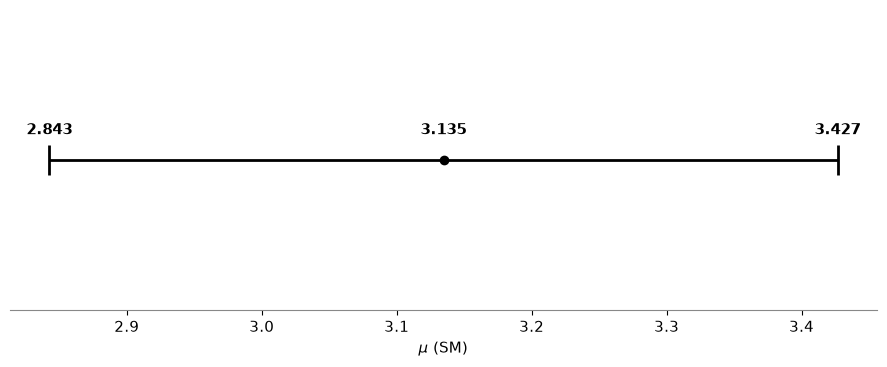

In [16]:
# Apresenta o intervalo para a renda média.
fig, ax = plt.subplots()
ax.hlines(0, ic_t95[0], ic_t95[1], color='black', linewidth=2)
ax.vlines(ic_t95, -0.05, 0.05, color='black', linewidth=2)
ax.plot(media_t, 0, 'o', color='black')

valores = (ic_t95[0], media_t, ic_t95[1])
for v in valores:
    ax.text(
        v, 0.1, f'{v:.3f}',
        ha='center', va='center', color='black', fontweight='bold',
    )

ax.set(xlabel='$μ$ (SM)', yticks=[], ylim=(-0.5, 0.5))
ax.spines['left'].set_visible(False)
fig.tight_layout()
plt.show()

**Figura 19 - Intervalo aproximado de 95% para a renda média.** A estimativa de 3,135 SM é acompanhada do intervalo de 2,843 a 3,427 SM. A largura expressa incerteza da média, não dispersão das rendas individuais. Fonte: CARUBBI, 2026.

#### 11.3.3. Interpretação

Obtivemos média de 3,135 SM e erro-padrão estimado de 0,149 SM. Com 399 graus de liberdade, o IC aproximado de 95% é **[2,843, 3,427] SM**.

O desvio-padrão amostral descreve a dispersão das rendas individuais. O erro-padrão estimado descreve a incerteza da média. A referência t é exata para amostras iid Normais. Nesta aplicação, sua validade é aproximada, pois a população é assimétrica.

A média da população completa, aproximadamente 3,000 SM, pertence ao intervalo observado. A disponibilidade desse valor é um recurso de conferência da simulação e não entra no cálculo dos limites.

## 12. Testes de hipóteses

### 12.1. Contexto

Queremos avaliar a afirmação de que **80% das pessoas da população simulada** têm rendimento domiciliar per capita inferior a 5 SM.

A proporção observada em uma amostra pode diferir de 80% por **variabilidade amostral**. Como avaliar se a diferença observada fornece evidência de que a proporção populacional é diferente de 80%?

### 12.2. Fundamentação teórica

**Formulação das hipóteses**

Para testar uma afirmação sobre um parâmetro populacional, formulamos a **hipótese nula** ($H_0$) e a **hipótese alternativa** ($H_1$) (Barbetta; Reis; Bornia, 2010, p. 199–200).

A **hipótese nula** ($H_0$) é a afirmação sobre o parâmetro populacional que serve de referência para avaliar os dados. Para entender se o resultado observado é incomum, perguntamos quais resultados esperaríamos se $H_0$ fosse verdadeira.

A **hipótese alternativa** ($H_1$) especifica quais valores do parâmetro, incompatíveis com $H_0$, queremos investigar. Ela orienta a busca por evidência nos dados (Montgomery; Runger, 2018, p. 194–195).

**Valor crítico na decisão do teste**

O **teste de hipóteses** avalia se os dados amostrais fornecem evidência suficiente para **rejeitar a hipótese nula** ($H_0$) em favor da **hipótese alternativa** ($H_1$) (Barbetta; Reis; Bornia, 2010, p. 200).

Antes de observar o resultado, fixamos o **nível de significância** $\alpha$. A **estatística de teste** é calculada a partir dos dados amostrais. Sua distribuição sob $H_0$ e as condições do modelo é a **distribuição de referência**.

A partir de $\alpha$, da distribuição de referência e de $H_1$, determinamos os **valores críticos**, que delimitam a **região de rejeição**. Rejeitamos $H_0$ quando a estatística observada pertence a essa região (Rudolph; Krois; Hartmann, 2023).

Em uma distribuição de referência contínua e simétrica, como a Normal padrão ou a $t$ de Student, a hipótese alternativa determina como distribuir a área de rejeição.

- No **teste unilateral à esquerda**, a região de rejeição ocupa a cauda esquerda e tem área $\alpha$.
- No **teste unilateral à direita**, a região de rejeição ocupa a cauda direita e tem área $\alpha$.
- No **teste bilateral** de caudas iguais, a região de rejeição ocupa as duas caudas, com área $\alpha/2$ em cada uma.

A **Figura 20** mostra onde ficam os valores críticos nos três tipos de teste.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/regioes_rejeicao_normal_paineis.png" alt="Três painéis da Normal padrão na ordem unilateral à esquerda, unilateral à direita e bilateral. As caudas sombreadas formam a região de rejeição, com área alfa nos testes unilaterais e alfa sobre dois por cauda no bilateral." style="width: 900px; max-width: 100%; height: auto;">
</div>

**Figura 20 - Regiões de rejeição pelo valor crítico.** As linhas tracejadas marcam os valores críticos da Normal padrão. Em cada painel, as regiões sombreadas somam $\alpha$ e indicam onde rejeitar $H_0$. O valor de $z_c$ depende de $\alpha$ e do tipo de teste. Adaptado de Rudolph, Krois e Hartmann (2023).

No exemplo da seção 12.1, $p$ é a proporção populacional de pessoas com rendimento abaixo de 5 SM. A hipótese nula $H_0\colon p=0{,}80$ estabelece **80% como referência**. A pergunta de pesquisa determina como formulamos $H_1$ (Montgomery; Runger, 2018, p. 195).

- **Bilateral** ($H_1\colon p\ne 0{,}80$) quando investigamos se a proporção difere de 80%.
- **Unilateral à esquerda** ($H_1\colon p<0{,}80$) quando investigamos se a proporção é menor que 80%.
- **Unilateral à direita** ($H_1\colon p>0{,}80$) quando investigamos se a proporção é maior que 80%.

Como a pergunta da seção 12.1 considera diferenças nos dois sentidos, a alternativa é **bilateral**. O painel (c) da Figura 20 ilustra essa lógica para a distribuição Normal. A seção 13 aplica o teste de escore bilateral para essa proporção.

**Valor-p na decisão do teste**

O **valor-p** responde à seguinte pergunta. Se $H_0$ fosse verdadeira e as condições do modelo fossem satisfeitas, qual seria a probabilidade de obter, em uma amostra de mesmo tamanho e pelo mesmo procedimento, um valor da estatística de teste **tão ou mais extremo que o observado**? Um valor-p pequeno indica que resultados assim seriam pouco frequentes sob $H_0$ (Morettin; Bussab, 2010, p. 348–350).

> O **valor-p**, também chamado de **probabilidade de significância**, é a probabilidade de obter, sob $H_0$ e as condições do modelo, um valor da estatística de teste **tão ou mais extremo que o observado**, segundo o critério do teste (Barbetta; Reis; Bornia, 2010, p. 203).
>
> Para o teste escolhido e os dados observados, o valor-p é o **menor nível de significância** $\alpha$ para o qual rejeitaríamos $H_0$ (Montgomery; Runger, 2018, p. 203; Pinheiro *et al.*, 2009, p. 223).

A **Figura 21** mostra como a hipótese alternativa determina as caudas usadas para obter o valor-p a partir da estatística observada $z$.

<div style="text-align: center">
<img src="https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u3_s01/barbetta_figura_8_6_paineis.png" alt="Três gráficos da Normal padrão. No teste unilateral à esquerda, a cauda esquerda está sombreada. No unilateral à direita, a cauda direita está sombreada. No bilateral, as duas caudas estão sombreadas e cada uma tem metade do valor-p." style="width: 760px; max-width: 100%; height: auto">
</div>

**Figura 21 - Valor-p em testes unilaterais e bilaterais.** Nos testes unilaterais, o valor-p corresponde à área na cauda indicada pela hipótese alternativa. No teste bilateral com referência Normal padrão, é a soma das áreas à esquerda de $-|z|$ e à direita de $|z|$. Adaptado de Barbetta, Reis e Bornia (2010, p. 214, Figura 8.6), com os painéis reordenados.

A regra de decisão compara o **valor-p** com o **nível de significância** $\alpha$ (Barbetta; Reis; Bornia, 2010, p. 214; Rudolph; Krois; Hartmann, 2023).

$$
\begin{aligned}
\boxed{\text{p} > \alpha} &\quad \Longrightarrow \quad \boxed{\text{não rejeitamos } H_0} \\
\boxed{\text{p} \leq \alpha} &\quad \Longrightarrow \quad \boxed{\text{rejeitamos } H_0}
\end{aligned}
$$

**Erros dos tipos I e II e nível de significância**

A decisão em um teste de hipóteses pode estar errada. Cometemos um **erro tipo I** (**falso positivo**) quando rejeitamos uma hipótese nula verdadeira e um **erro tipo II** (**falso negativo**) quando deixamos de rejeitar uma hipótese nula falsa (Rudolph; Krois; Hartmann, 2023).

A Tabela 14 mostra as decisões possíveis e suas probabilidades conforme $H_0$ seja verdadeira ou falsa.

| Decisão do teste | $H_0$ verdadeira | $H_0$ falsa |
|---|---|---|
| Aceitar $H_0$ | Decisão correta (probabilidade $\geq 1-\alpha$) | **Erro tipo II** (probabilidade $\beta$) |
| Rejeitar $H_0$ | **Erro tipo I** (probabilidade $\leq \alpha$) | Decisão correta (probabilidade $1-\beta$, o **poder do teste**) |

**Tabela 14 - Decisões e probabilidades em testes de hipóteses.** Para um mesmo valor do parâmetro populacional, rejeitar e não rejeitar $H_0$ são decisões complementares, cujas probabilidades somam 1. Fonte: adaptação de Barbetta, Reis e Bornia (2010, p. 224–225).

A Tabela 14 descreve testes que controlam o erro tipo I pelo nível nominal $\alpha$. As igualdades a seguir valem quando a probabilidade de erro tipo I atinge esse nível. Para calcular $\beta$, fixamos um valor do parâmetro sob a alternativa (Barbetta; Reis; Bornia, 2010, p. 206; Montgomery; Runger, 2018, p. 197–199).

$$
\begin{aligned}
P(\text{erro tipo I}) &= P(\text{rejeitar } H_0 \mid H_0 \text{ verdadeira}) = \alpha, \\
P(\text{erro tipo II}) &= P(\text{não rejeitar } H_0 \mid H_0 \text{ falsa}) = \beta.
\end{aligned}
$$

As probabilidades das decisões corretas vêm dos eventos complementares.

$$
\begin{aligned}
P(\text{não rejeitar } H_0 \mid H_0 \text{ verdadeira}) &= 1 - \alpha, \\
P(\text{rejeitar } H_0 \mid H_0 \text{ falsa}) &= 1 - \beta.
\end{aligned}
$$

O **poder do teste**, $1-\beta$, é a probabilidade de rejeitar $H_0$ para um valor específico do parâmetro sob a alternativa (Barbetta; Reis; Bornia, 2010, p. 225).

A probabilidade efetiva de erro tipo I depende da regra do teste. Em testes discretos que controlam o erro tipo I, ela pode ser menor que $\alpha$. Com uma distribuição de referência aproximada, também pode ultrapassar o nível nominal.

Quando não rejeitamos $H_0$, dizemos que os dados estão **em conformidade com a hipótese nula** ao nível de significância adotado. A conclusão é que os dados fornecem evidência insuficiente para rejeitá-la (Barbetta; Reis; Bornia, 2010, p. 206).

Sobre isso, R. A. Fisher, considerado o pai da estatística experimental, escreveu:

> “A hipótese nula pode ou não ser impugnada pelos resultados de um experimento. Ela nunca pode ser provada, mas pode ser desaprovada no curso da experimentação” (Fisher *apud* Barbetta; Reis; Bornia, 2010, p. 206).

## 13. Teste para proporção populacional

### 13.1. Contexto

Retomamos a afirmação da seção 12.1 de que **80% das pessoas da população simulada** têm rendimento domiciliar per capita abaixo de 5 SM. Na amostra da seção 10, **315 de 400 pessoas (78,75%)** têm rendimento abaixo desse limite.

Ao **nível de significância de 5%**, os dados fornecem evidência suficiente de que a proporção populacional difere de 80%?

### 13.2. Fundamentação teórica

**Modelo e aproximação Normal**

Cada observação indica se o atributo de interesse está presente ou ausente. Se as $n$ observações são independentes e têm a mesma probabilidade $p$ de apresentar o atributo, a contagem $X$ segue uma **distribuição binomial**. Sob $H_0$, usamos $p=p_0$ e verificamos as **contagens esperadas** $np_0$ e $n(1-p_0)$. Para usar a aproximação Normal, adotamos como critério prático **pelo menos cinco observações esperadas em cada categoria** (Barbetta; Reis; Bornia, 2010, p. 213).

**Estatística do teste de escore**

Como na seção 10.2, escrevemos $\widehat P=X/n$ para a proporção amostral antes de observar os dados e $\hat p=x/n$ para a proporção obtida após observar a contagem $x$.

Usamos o **teste de escore sem correção de continuidade**. A estatística expressa a diferença entre a proporção amostral $\widehat P$ e o valor de referência $p_0$ em unidades do **erro-padrão calculado sob $H_0$** (Barbetta; Reis; Bornia, 2010, p. 213, Eq. 8.4; Montgomery; Runger, 2018, seção 9.5.1, Eq. 9.41).

$$
Z_0=\frac{\widehat P-p_0}{\sqrt{p_0(1-p_0)/n}}.
\tag{2.11}
$$

Na equação (2.11), substituímos $\widehat P$ por $\hat p$ para obter $z$, o **valor observado da estatística do teste**.

**Valor-p bilateral**

Sob $H_0$, usamos a **Normal padrão** como distribuição de referência aproximada para $Z_0$. O módulo $|z|$ é a distância entre $z$ e zero na escala padronizada. Como $H_1\colon p\ne p_0$ considera diferenças nos dois sentidos, o **valor-p** é a soma das áreas à esquerda de $-|z|$ e à direita de $|z|$ (Barbetta; Reis; Bornia, 2010, p. 214). O painel bilateral da **Figura 21** ilustra essas duas áreas.

### 13.3. Aplicação

Usamos a amostra de 400 observações selecionadas com reposição na seção 10. Seja $p$ a proporção populacional de pessoas com rendimento domiciliar per capita abaixo de 5 SM.

- **Hipótese nula** ($H_0\colon p=0{,}80$). A proporção populacional é de 80%.
- **Hipótese alternativa** ($H_1\colon p\ne0{,}80$). A proporção populacional é menor ou maior que 80%.

Aplicamos o **teste de escore bilateral** ao nível de significância de **5%**. Sob $H_0$, esperamos 320 observações abaixo de 5 SM e 80 com rendimento igual ou superior a esse limite. Essas contagens sustentam a aproximação pela Normal padrão.

#### 13.3.1. Implementação sem pacotes

Usamos a proporção observada $\hat p$ na equação (2.11) para obter $z$. A função <code>stats.norm.sf</code> calcula a área à direita de $|z|$ na Normal padrão. Multiplicamos essa área por dois para obter o valor-p bilateral.

In [17]:
# Define a padronização de uma estimativa em relação a uma referência.
def est_pad(est, ref, ep):
    """Expressa a diferença em unidades de erro-padrão."""
    return (est - ref) / ep

In [18]:
# Calcula a estatística de escore e o valor-p bilateral.
p0 = 0.80
alfa_p = 0.05
ep_h0 = ep_prop(p0, n_inf, N, rep=True)
z_prop = est_pad(phat, p0, ep_h0)
p_prop = 2 * stats.norm.sf(abs(z_prop))

# Resume os resultados do teste.
decisao_p = 'Rejeitar H0' if p_prop <= alfa_p else 'Não rejeitar H0'
display(pd.DataFrame({
    'Contagem observada': [x_inf],
    'Proporção amostral': [f'{phat:.2%}'],
    'Estatística z': [z_prop],
    'Valor-p bilateral': [p_prop],
    'Decisão a 5%': [decisao_p],
}))

,Contagem observada,Proporção amostral,Estatística z,Valor-p bilateral,Decisão a 5%
0,315,78.75%,-0.625000,0.531971,Não rejeitar H0


**Tabela 15 - Resultado do teste de escore para a proporção.** Na amostra de 400 observações, 315 pessoas têm rendimento abaixo de 5 SM. O valor-p de 0,531971 leva à não rejeição de $H_0$ ao nível de 5%. Fonte: CARUBBI, 2026.

#### 13.3.2. Implementação com pacotes

Em <code>proportions_ztest</code>, <code>value=p0</code> fixa a hipótese e <code>alternative='two-sided'</code> fixa a alternativa. Com <code>prop_var=p0</code>, a função calcula a variância sob $H_0$. Ela retorna diretamente a **estatística $z$** e o **valor-p bilateral**. [Documentação de proportions_ztest](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportions_ztest.html) (STATSMODELS DEVELOPERS, 2025).

In [19]:
# Confere a estatística e o valor-p com statsmodels.
z_pac, p_pac = proportions_ztest(
    count=x_inf, nobs=n_inf, value=p0,
    alternative='two-sided', prop_var=p0,
)
display(pd.DataFrame({
    'z pela expressão': [z_prop],
    'z pelo statsmodels': [z_pac],
    'Valor-p pela expressão': [p_prop],
    'Valor-p pelo statsmodels': [p_pac],
}))

,z pela expressão,z pelo statsmodels,Valor-p pela expressão,Valor-p pelo statsmodels
0,-0.625000,-0.625000,0.531971,0.531971


**Tabela 16 - Conferência do teste de escore com statsmodels.** A função retorna a mesma estatística $z$ e o mesmo valor-p do cálculo direto pela equação (2.11). Fonte: CARUBBI, 2026.

A **Figura 22** mostra as duas caudas que somam o valor-p da amostra observada.

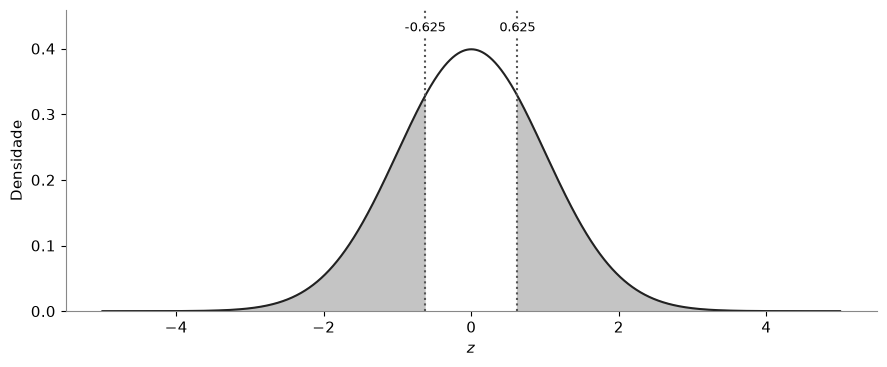

In [20]:
# Mostra as duas caudas que compõem o valor-p bilateral.
eixo_z = np.linspace(-5, 5, 4001)
dens_z = stats.norm.pdf(eixo_z)
limite = abs(z_prop)

fig, ax = plt.subplots()
ax.plot(eixo_z, dens_z, color='#222222')
ax.fill_between(eixo_z, dens_z, where=np.abs(eixo_z) >= limite,
                color='#c4c4c4')
for corte in (-limite, limite):
    ax.axvline(corte, color='#555555', linestyle=':')
    ax.text(corte, 0.94, f'{corte:.3f}', transform=ax.get_xaxis_transform(),
            ha='center', va='center', fontsize=9,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})

ax.set(xlabel='$z$', ylabel='Densidade', ylim=(0, 1.15 * dens_z.max()))
fig.tight_layout()
plt.show()

**Figura 22 - Caudas do valor-p no teste de escore bilateral.** As áreas sombreadas à esquerda de $-0{,}625$ e à direita de $0{,}625$ somam o valor-p de **0,531971**. Fonte: CARUBBI, 2026.

#### 13.3.3. Interpretação

A proporção observada de **78,75%** está **1,25 ponto percentual** abaixo da referência de 80%. Como o valor-p bilateral é **0,531971**, não rejeitamos $H_0$ ao nível de 5%. Os dados fornecem evidência insuficiente para concluir que a proporção populacional difere de 80%.

Expresse a magnitude da diferença em pontos percentuais e apresente o valor-p junto à decisão do teste (American Statistical Association, 2016).

## 14. Teste para média populacional

### 14.1. Contexto

Na mesma amostra de 400 observações, o rendimento domiciliar per capita médio foi de 3,135 SM. A pesquisa avalia a afirmação de que essa média é de 3 SM na população.

Ao nível de significância de 5%, os dados fornecem evidência suficiente de que a média populacional difere de 3 SM?

### 14.2. Fundamentação teórica

**Variância populacional conhecida**

Para testar $H_0\colon \mu=\mu_0$, comparamos a média amostral observada $\bar x$ com o valor de referência $\mu_0$. Quando a variância populacional $\sigma^2$ é conhecida, o **erro-padrão da média** é $\sigma/\sqrt n$, como na seção 11.2. A estatística expressa a diferença $\bar x-\mu_0$ em unidades desse erro-padrão. Adotamos a forma da equação (8.8) de Barbetta, Reis e Bornia (2010, p. 218).

$$
z=\frac{(\bar x-\mu_0)\cdot\sqrt n}{\sigma}.
\tag{2.12}
$$

Se as $n$ observações são independentes e vêm de uma população Normal, a **Normal padrão** é a distribuição de referência sob $H_0$.

**Variância populacional desconhecida**

Quando $\sigma^2$ é desconhecida, estimamos o erro-padrão da média por $S/\sqrt n$, em que $S$ é o desvio-padrão amostral. A estatística do **teste $t$ de Student para uma amostra** expressa a diferença entre a média amostral $\bar X$ e o valor de referência $\mu_0$ em unidades do **erro-padrão estimado**.

$$
T=\frac{\bar X-\mu_0}{S/\sqrt n}.
\tag{2.13}
$$

Depois de observar a amostra, substituímos $\bar X$ pela média observada $\bar x$ e $S$ pelo desvio-padrão observado $s$. Assim, obtemos $t_{\mathrm{obs}}$, o **valor observado da estatística**.

Se as observações são independentes e vêm de uma população Normal, $T$ segue exatamente a distribuição $t$ de Student com $n-1$ **graus de liberdade** sob $H_0$. Para observações independentes de uma população não Normal com variância finita, podemos usar essa referência como aproximação em amostras grandes, conforme discutido na seção 11.2 (Barbetta; Reis; Bornia, 2010, p. 219–220; Montgomery; Runger, 2018, p. 215–216).

### 14.3. Aplicação

Adotamos $H_0:\mu=3$ SM e $H_1:\mu\ne3$ SM, com $\alpha=0{,}05$. Reutilizaremos a média, o desvio-padrão e o erro-padrão da mesma amostra de 400 pessoas.

#### 14.3.1. Implementação sem pacotes

Reutilize a função de padronização. O pacote fornecerá a probabilidade nas duas caudas da referência t.

In [21]:
# Padroniza a média e calcula o valor-p bilateral aproximado.
mu0 = 3.0
alfa_t = 0.05
t_obs = est_pad(media_t, mu0, ep_t)
p_t = 2 * stats.t.sf(abs(t_obs), df=gl_t)
print(f't = {t_obs:.6f}, graus de liberdade = {gl_t}')
print(f'Valor-p bilateral = {p_t:.8f}')
print('Decisão:', 'rejeitar H0' if p_t <= alfa_t else 'não rejeitar H0')

t = 0.906584, graus de liberdade = 399
Valor-p bilateral = 0.36517401
Decisão: não rejeitar H0


#### 14.3.2. Implementação com pacotes

<code>stats.ttest_1samp</code> recebe as rendas individuais, <code>popmean=mu0</code> e <code>alternative='two-sided'</code>. A alternativa corresponde à pergunta sobre diferença em qualquer direção. [Documentação de ttest_1samp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html) (SCIPY COMMUNITY, 2026).

In [22]:
# Confere o teste t bilateral com SciPy.
teste_t = stats.ttest_1samp(am_inf, popmean=mu0, alternative='two-sided')
display(pd.DataFrame({
    'Med.': ['t', 'p-val'],
    'Expr.': [t_obs, p_t],
    'Pac.': [teste_t.statistic, teste_t.pvalue],
}))

,Med.,Expr.,Pac.
0,t,0.906584,0.906584
1,p-val,0.365174,0.365174


**Tabela 17 - Conferência do teste para a renda média.** As implementações coincidem em t ≈ 0,907 e valor-p bilateral de 0,365174. A hipótese de média 3 SM não é rejeitada a 5%. A inferência é aproximada para a população assimétrica. **Legenda.** Med. = medida. t = estatística observada do teste da média. p-val = valor-p bilateral. Expr. = cálculo pela expressão. Pac. = cálculo pelo SciPy. SM = salário mínimo de referência. Fonte: CARUBBI, 2026.

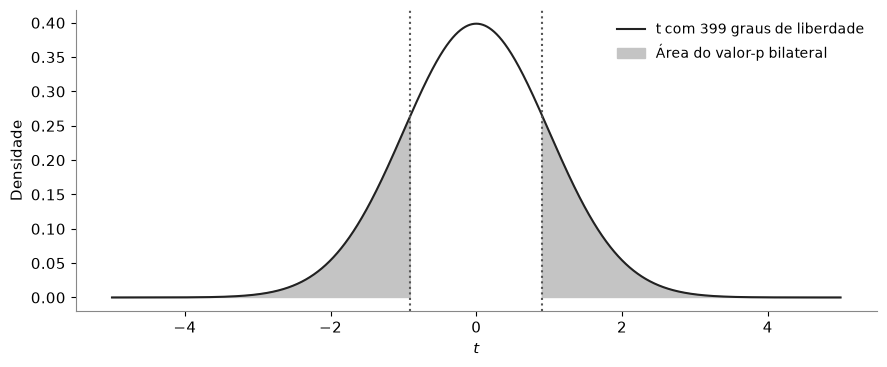

In [23]:
# Destaca as duas caudas que definem o valor-p bilateral.
eixo_t = np.linspace(-5, 5, 3001)
dens_t = stats.t.pdf(eixo_t, df=gl_t)
fig, ax = plt.subplots()
ax.plot(eixo_t, dens_t, color='#222222', label=f't com {gl_t} graus de liberdade')
ax.fill_between(eixo_t, dens_t, where=(np.abs(eixo_t) >= abs(t_obs)), color='#c4c4c4', label='Área do valor-p bilateral')
for ref in [-abs(t_obs), abs(t_obs)]:
    ax.axvline(ref, color='#555555', linestyle=':')
ax.set(xlabel='$t$', ylabel='Densidade')
ax.legend()
fig.tight_layout()
plt.show()

**Figura 23 - Caudas do teste bilateral para a renda média.** Com 399 graus de liberdade, as áreas além de ±0,907 somam valor-p de aproximadamente 0,365174. Fonte: CARUBBI, 2026.

#### 14.3.3. Interpretação

A média amostral observada é 3,135 SM, diferença de 0,135 SM para a referência. Obtivemos t ≈ 0,907 e valor-p bilateral de **0,365174**. Não rejeitamos a hipótese de média 3 SM ao nível de 5%, sem concluir que ela foi comprovada.

O IC bilateral aproximado de 95% da seção 11 contém 3 SM. Como usamos a mesma amostra, a mesma referência t e níveis compatíveis, intervalo e teste produzem decisões equivalentes.

A população simulada é assimétrica. O uso de n = 400 sustenta aqui uma inferência aproximada, sem tornar a distribuição t exata ou eliminar a necessidade de avaliar as condições do procedimento.

## 15. Poder de um teste e tamanho da amostra

Como vimos na seção 12.2, o **poder de um teste**, $1-\beta$, é a probabilidade de rejeitar $H_0$ para um valor específico do parâmetro sob a alternativa (Barbetta; Reis; Bornia, 2010, p. 225). No planejamento, usamos essa probabilidade para escolher um tamanho de amostra adequado à diferença que queremos detectar.

Para planejar o teste $t$ bilateral de $H_0\colon \mu=3$ SM, consideramos uma diferença de interesse de **0,50 SM**. Tomamos $\mu=3{,}50$ SM como média populacional hipotética, em um modelo Normal com desvio-padrão $\sigma=3$ SM. Com o nível de significância fixado em 5%, comparamos dois tamanhos de amostra.

Para calcular o poder na **Tabela 18**, usamos <code>TTestPower.power()</code> com o efeito padronizado $d=|\mu-\mu_0|/\sigma$ (<code>effect_size</code>), os tamanhos de amostra de 100 e 400 (<code>nobs</code>) e o nível de significância de 5% (<code>alpha</code>). [Documentação do statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.power.TTestPower.power.html)

In [24]:
# Define as condições de planejamento.
mu_h0 = 3.0
mu_alt = 3.5
sigma = 3.0
alfa = 0.05
n = np.array([100, 400])
delta = mu_alt - mu_h0
d = abs(delta) / sigma

# Calcula o erro-padrão e o poder bilateral.
ep = sigma / np.sqrt(n)
poder_t = TTestPower()
poder = poder_t.power(
    effect_size=d, nobs=n, alpha=alfa,
    alternative='two-sided',
)

# Exibe os resultados dos dois cenários.
tabela = pd.DataFrame({
    'Tamanho da amostra': n,
    'Erro-padrão (SM)': [f'{valor:.2f}' for valor in ep],
    'Poder do teste': [f'{valor:.2%}' for valor in poder],
}, index=['Cenário 1', 'Cenário 2'])
display(tabela.T)

,Cenário 1,Cenário 2
Tamanho da amostra,100,400
Erro-padrão (SM),0.30,0.15
Poder do teste,37.86%,91.39%


**Tabela 18 - Cálculo do poder do teste $t$ bilateral em dois cenários.** Para a mesma diferença de 0,50 SM, a amostra maior tem erro-padrão menor e maior poder. Fonte: CARUBBI, 2026.

A **Figura 24** estende a comparação a outras médias verdadeiras, seguindo a Figura 8.10 de Barbetta, Reis e Bornia (2010, p. 226). Para as curvas, usamos o mesmo cálculo de poder do teste $t$ (Montgomery; Runger, 2018, p. 220–221).

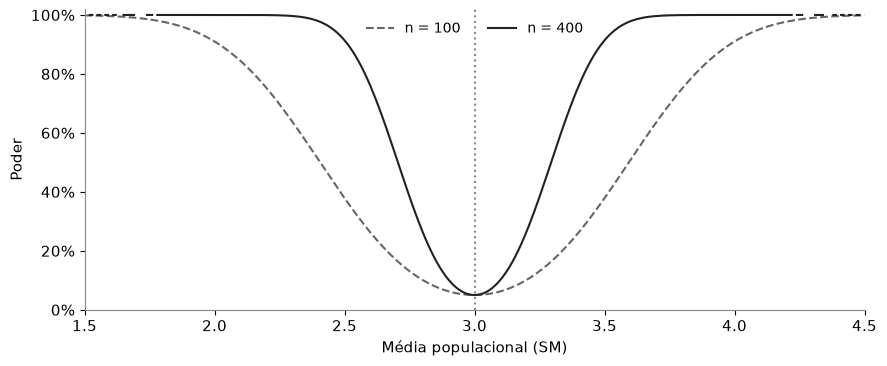

In [25]:
# Calcula o tamanho de efeito para cada média da curva.
medias_hipoteticas = np.linspace(1.5, 4.5, 301)
efeitos = abs(medias_hipoteticas - mu_h0) / sigma

# Compara as curvas para os dois tamanhos de amostra.
fig, ax = plt.subplots()
for tamanho, cor, estilo in zip(n, ('#666666', '#222222'), ('--', '-')):
    poder_curva = poder_t.power(
        effect_size=efeitos, nobs=tamanho, alpha=alfa,
        alternative='two-sided',
    )
    ax.plot(medias_hipoteticas, poder_curva, color=cor, linestyle=estilo, label=f'n = {tamanho}')

ax.axvline(mu_h0, color='#888888', linestyle=':')
ax.set(xlabel='Média populacional (SM)', ylabel='Poder',
       xlim=(1.5, 4.5), ylim=(0, 1.02))
ax.yaxis.set_major_formatter('{x:.0%}')
ax.legend(loc='upper center', ncols=2)
fig.tight_layout()
plt.show()

**Figura 24 - Curvas de poder do teste $t$ bilateral para a média.** Modelo Normal de planejamento com $\sigma=3$ SM e $\alpha=5\%$. Na linha pontilhada, a média verdadeira coincide com $\mu_0=3$ SM e a probabilidade de rejeição é de 5% (erro tipo I). O poder cresce à medida que a média verdadeira se afasta de 3 SM. Para a mesma diferença, a curva de $n=400$ apresenta maior poder que a de $n=100$. Adaptado da Figura 8.10 (Barbetta; Reis; Bornia, 2010, p. 226).

No planejamento, podemos fixar a diferença de interesse e o poder desejado. **Quantas observações são necessárias para detectar uma diferença de 0,5 SM com pelo menos 80% de poder?** Sob as mesmas condições da Figura 24, usamos <code>solve_power</code> para obter o tamanho necessário e arredondamos o resultado para cima.

In [26]:
# Calcula o tamanho da amostra para atingir 80% de poder.
meta = 0.80
n_estimado = poder_t.solve_power(
    effect_size=d, power=meta, alpha=alfa,
    alternative='two-sided',
)
n_min = math.ceil(n_estimado)

# Confere o poder no tamanho inteiro adotado.
poder_min = poder_t.power(
    effect_size=d, nobs=n_min, alpha=alfa,
    alternative='two-sided',
)
print(f'Tamanho amostral mínimo: {n_min}')
print(f'Poder com n = {n_min}: {poder_min:.1%}')

Tamanho amostral mínimo: 285
Poder com n = 285: 80.1%


## 16. Estudo e exercícios

### 16.1. Materiais didáticos

Consulte as leituras conforme o tema que deseja retomar.

- **Estimação pontual e intervalos de confiança (seções 9–11).** Barbetta, Reis e Bornia (2010), seção 7.3, p. 179–191. Como complemento, consulte Montgomery e Runger (2018), seções 8.2 e 8.4.
- **Hipóteses, valor-p e erros (seção 12).** Barbetta, Reis e Bornia (2010), seções 8.1–8.5, p. 198–210, e abordagem pelo valor-p na p. 214. Para aprofundar a interpretação do valor-p, consulte a American Statistical Association (2016).
- **Teste de proporção (seção 13).** Barbetta, Reis e Bornia (2010), seção 8.7, p. 212–216. Como complemento, consulte Montgomery e Runger (2018), seção 9.5.1.
- **Teste da média (seção 14).** Barbetta, Reis e Bornia (2010), seção 8.8, p. 217–221. Como complemento, consulte Montgomery e Runger (2018), seção 9.3.
- **Poder do teste e tamanho da amostra (seção 15).** Barbetta, Reis e Bornia (2010), seção 8.10, p. 224–228, até o fim do planejamento para a média. Como complemento, consulte Montgomery e Runger (2018), seção 9.3.2, p. 220–221.

Consulte a documentação das funções nos links das aplicações e na seção 17.

### 16.2. Exercícios indicados

Resolva os exercícios após as aulas. Consulte os enunciados em Barbetta, Reis e Bornia (2010) e justifique cada conclusão no contexto do problema.

- **Intervalo de confiança para proporção.** Capítulo 7, exercício 10, p. 191. Construa um intervalo de 95% para a proporção de edifícios com problemas estéticos.
- **Intervalo de confiança para média.** Capítulo 7, exercício 12, p. 191. Construa um intervalo de 99% para o diâmetro médio dos furos e interprete o resultado em relação a 100 mm.
- **Teste de proporção.** Capítulo 8, exercício 15, p. 217. Verifique se os 40 acertos em 60 questões de certo ou errado dão evidência de uma taxa de acertos acima de 50%, ao nível de 5%.
- **Teste $t$ para média.** Capítulo 8, exercício 19, p. 221. Verifique se a nova composição aumenta a durabilidade média dos pneus, ao nível de 1%.

No exercício 12 do capítulo 7, use a distribuição $t$ com 35 graus de liberdade, conforme a seção 11.2.

## 17. Referência

1. AMERICAN STATISTICAL ASSOCIATION. *American Statistical Association releases statement on statistical significance and p-values*. Alexandria: ASA, 7 mar. 2016. [Declaração e princípios sobre valores-p](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf). Acesso em: 12 nov. 2026.

2. BARBETTA, Pedro Alberto, REIS, Marcelo Menezes e BORNIA, Antonio Cezar. *Estatística para cursos de engenharia e informática*. 3. ed. São Paulo: Atlas, 2010. Seções 2.2.1, 7.1–7.3, 8.1–8.8 e 8.10.

3. BROWN, Lawrence D.; CAI, T. Tony; DASGUPTA, Anirban. Interval estimation for a binomial proportion. *Statistical Science*, [S. l.], v. 16, n. 2, p. 101–133, maio 2001. DOI: 10.1214/ss/1009213286. Disponível em: <https://projecteuclid.org/journals/statistical-science/volume-16/issue-2/Interval-Estimation-for-a-Binomial-Proportion/10.1214/ss/1009213286.pdf>. Acesso em: 20 nov. 2026.

4. MONTGOMERY, Douglas C. e RUNGER, George C. *Applied Statistics and Probability for Engineers*. 7. ed. Hoboken: Wiley, 2018. Seções 7.2, 8.2, 8.4, 9.1, 9.3 e 9.5.1.

5. MORETTIN, Pedro Alberto e BUSSAB, Wilton de Oliveira. *Estatística básica*. 6. ed. São Paulo: Saraiva, 2010. Seção 10.8, p. 277-280.

6. NUMPY DEVELOPERS. *NumPy v2.5 manual*. 2026. [Generator.choice](https://numpy.org/doc/2.5/reference/random/generated/numpy.random.Generator.choice.html) e [rotinas estatísticas](https://numpy.org/doc/2.5/reference/routines.statistics.html). Acesso em: 12 nov. 2026.

7. PANDAS DEVELOPMENT TEAM. *pandas documentation*. 2026. [DataFrame.nsmallest](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nsmallest.html) e [Series.mean](https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html). Acesso em: 12 nov. 2026.

8. PINHEIRO, João Ismael D., CUNHA, Sonia Baptista da, CARVAJAL, Santiago Ramírez e GOMES, Gastão Coelho. *Estatística básica: a arte de trabalhar com dados*. Rio de Janeiro: Elsevier, 2009. Seção 6.1, exemplos 6.1-6.2, p. 156-159, e seção 8.5, p. 223.

9. RUDOLPH, Annette; KROIS, Joachim; HARTMANN, Kai. *Statistics and geodata analysis using Python (SOGA-Py)*. Berlin: Freie Universität Berlin, Department of Earth Sciences, 2023. Disponível em: <https://www.geo.fu-berlin.de/en/v/soga-py>. Acesso em: 21 nov. 2026.

10. SCIPY COMMUNITY. *SciPy v1.18.0 manual*. 2026. [Estatística](https://docs.scipy.org/doc/scipy/reference/stats.html), com verbetes norm, binom, t, sem e ttest_1samp. Acesso em: 12 nov. 2026.

11. STATSMODELS DEVELOPERS. *Statsmodels 0.14.6 documentation*. 2025. [proportion_confint](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportion_confint.html) e [proportions_ztest](https://www.statsmodels.org/v0.14.6/generated/statsmodels.stats.proportion.proportions_ztest.html). Acesso em: 12 nov. 2026.

12. WALD, Abraham. Tests of statistical hypotheses concerning several parameters when the number of observations is large. *Transactions of the American Mathematical Society*, [S. l.], v. 54, n. 3, p. 426–482, nov. 1943. DOI: 10.1090/S0002-9947-1943-0012401-3. Disponível em: <https://www.ams.org/tran/1943-054-03/S0002-9947-1943-0012401-3/S0002-9947-1943-0012401-3.pdf>. Acesso em: 20 nov. 2026.

13. ZHENG, Tian; YING, Zhiliang. Columbia University statistics. In: AGRESTI, Alan; MENG, Xiao-Li (ed.). *Strength in numbers: the rising of academic statistics departments in the U. S.* New York: Springer, 2012. p. 27–38. DOI: 10.1007/978-1-4614-3649-2_3. Disponível em: <https://stat.columbia.edu/wp-content/uploads/2014/02/StatDeptHistory.pdf>. Acesso em: 20 nov. 2026.